# Bayesian Logistic Disease Progress Curves — Case Study 2 (SY Monument, 2024)

**Paper:** *Bayesian Logistic Disease Progress Curves for Modeling Plant Disease Epidemics* — Claudio D. Silva Jr. et al., Research Square preprint `rs-11484962/v1` (posted 2026-11-12; under review at *Plant Methods*). DOI: [10.21203/rs.3.rs-11484962/v1](https://doi.org/10.21203/rs.3.rs-11484962/v1)

**Author code:** [`ClaudioDSJr11/Bayesian-Logistic-Disease-Progress-Curve-Paper`](https://github.com/ClaudioDSJr11/Bayesian-Logistic-Disease-Progress-Curve-Paper) pinned at commit `2a4a7f5317049fb0adca5fc8e9fd0fbf6874a836` — file `Bay LDPC paper analysis.Rmd`.

**Purpose.** Reproduce the paper's **case study 2**: fit the Bayesian logistic disease progress curve (three jointly estimated parameters *K* maximum disease potential, *r* apparent infection rate, *y₀* initial severity, plus Beta-likelihood precision *φ*) in JAGS to stripe rust severity observed on cv. SY Monument in 2024 (treatment 2), compute posterior summaries, in-sample 95% posterior predictive coverage, and the paper's prior-prediction figure (Figure 1).

**Exact scope.** Case study 2 only: data chunk, prior-prediction chunk, case-study-2 model fit, posterior summaries, diagnostics, predictive check, and Figures 1, 7 and 8. Case study 1 (treatment contrasts), the supplementary random-block model, and supplementary figures are **not** executed.

**Execution status.** This notebook was fully executed top-to-bottom on a fresh Google Colab **CPU** runtime (see the validation record at the end). The scientific computation is the authors' own R code, run verbatim; Python cells are only a launcher that writes the pinned R source and calls `Rscript` (the Colab CLI used for validation runs a Python kernel).

**AI-assisted orchestration statement.** The R scientific code below is the authors' pinned code copied verbatim (chunk subset); the Python orchestration, installation cells, and figure-export glue were written for this notebook. The authors did not provide this Colab implementation. The executed example and listed checks were validated, but untested behavior is not guaranteed.

**日本語要約:** 本ノートブックは論文「Bayesian Logistic Disease Progress Curves」のケーススタディ2（SY Monument・2024年・処理2）の最小再現です。JAGSによるベイズロジスティック病害進展曲線（K, r, y₀, φ）のMCMC推定、事後分布要約、95%事後予測区間のカバレッジ、事前予測図（Figure 1）を実行します。科学計算は著者らのRコード（commit `2a4a7f5`）をそのまま使用し、PythonセルはRの起動器に過ぎません。ケーススタディ1と補足モデルは対象外です。CPUランタイムのみで動作し、GPUは不要です。

## Runtime selection and how to run

**Select a standard Colab CPU runtime** (`ランタイム` → `ランタイムのタイプを変更` → `CPU`). No GPU is used anywhere in the authors' code (pure MCMC on a small data set), so a T4 would add nothing; this notebook was validated on CPU only.

**Run all** (`ランタイム` → `すべてのセルを実行`). Expected duration on the CPU runtime: about 5–10 minutes total — the largest parts are R package installation (~2–5 min) and the JAGS MCMC (<1–3 min). Downloads: the 36 KB data workbook plus apt/R packages (a few hundred MB installed).

**Limitations.** A single case study is a minimal demonstration, not verification of the paper's dataset-level results (case-study-1 contrasts, cross-season coverage 44.4%, AUDPC comparisons are out of scope). MCMC results vary slightly between runs; the authors' own seed (`set.seed(1996)`) is kept for the prior-prediction chunk. The repository has no LICENSE file — reuse the authors' code with attribution.

**日本語:** 標準の**CPU**ランタイムを選択してください（GPU不要）。`すべてのセルを実行`で約5〜10分です。単一事例の最小再現であり、論文のデータセット全体の結果検証ではありません。

### 1. Install JAGS (system)

The authors fit their model with **JAGS** through the R package **rjags**, so the JAGS system library must be installed first (`apt-get install jags`). This cell also prints the R and JAGS versions actually used. *Expect:* version strings, no errors.

**日本語:** 著者コードは rjags（JAGS本体にリンク）を使うため、まずシステムのJAGSをaptで導入し、R/JAGSのバージョンを表示します。

In [ ]:
import subprocess

subprocess.run(["apt-get", "-qq", "update"], check=True)
subprocess.run(["apt-get", "install", "-y", "jags"], check=True)
subprocess.run(["jags", "--version"], check=False)

r_ver = subprocess.run(["Rscript", "-e", "cat(R.version.string)"], check=True, capture_output=True, text=True)
print(r_ver.stdout)

R version 4.6.1 (2026-06-24)


### 2. Install the authors' R packages

The authors load `readxl`, `tidyverse`, `janitor`, `rjags`, and `gridExtra` (plus `coda`, rjags' sampling companion). On Colab's Linux image we install prebuilt Ubuntu binaries from the Posit Package Manager for speed, with a CRAN source fallback; **rjags is compiled against the system JAGS installed above.** The cell ends by printing installed versions of every required package and fails loudly if any is missing. *Expect:* install logs and a final version list.

**日本語:** 著者コードが必要とするRパッケージを導入します（Ubuntuバイナリを優先し、不足分はCRANソースにフォールバック）。rjagsは上で入れたJAGSにリンクしてビルドされます。最後に全パッケージのバージョンを表示し、欠落があれば停止します。

In [ ]:
from pathlib import Path
import subprocess

codename = ""
for line in Path("/etc/os-release").read_text().splitlines():
    if line.startswith("VERSION_CODENAME="):
        codename = line.split("=", 1)[1].strip()
print("Ubuntu codename:", codename)

install_r = f"""
options(HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(),
        paste(getRversion(), R.version$platform, R.version$arch, R.version$os)))
options(repos = c(CRAN = "https://cloud.r-project.org"))
pkgs <- c("readxl", "tidyverse", "janitor", "gridExtra", "coda")
install.packages(pkgs, repos = "https://packagemanager.posit.co/cran/__linux__/{codename}/latest")
install.packages("rjags", repos = "https://packagemanager.posit.co/cran/__linux__/{codename}/latest")
missing <- pkgs[!vapply(pkgs, requireNamespace, logical(1), quietly = TRUE)]
if (length(missing) || !requireNamespace("rjags", quietly = TRUE)) {{
  message("Falling back to CRAN source for: ", paste(c(missing, "rjags"), collapse = ", "))
  install.packages(c(missing, "rjags"))
}}
need <- c(pkgs, "rjags")
still <- need[!vapply(need, requireNamespace, logical(1), quietly = TRUE)]
if (length(still)) stop("Missing required R packages: ", paste(still, collapse = ", "))
for (p in need) cat(p, as.character(packageVersion(p)), "\n")
"""
Path("/content/install_packages.R").write_text(install_r)
subprocess.run(["Rscript", "/content/install_packages.R"], check=True, timeout=1800)

Ubuntu codename: noble


CompletedProcess(args=['Rscript', '/content/install_packages.R'], returncode=0)

### 3. Download the pinned data workbook (36 KB)

The case studies read `Disease long - FRL.xlsx` from the authors' repository at the pinned commit. We fetch the exact raw file, then verify (a) the expected byte size (36,229), (b) the **git blob SHA-1** `362edf6…` (identical to the GitHub tree entry at the pinned commit — this guarantees the bytes match what the author committed), and (c) the `PK` ZIP signature of a valid xlsx. *Expect:* `verified` plus the SHA.

**日本語:** 著者リポジトリ（commit `2a4a7f5`）から生のxlsxを取得し、バイト数・git blob SHA-1・ZIPシグネチャを検証します。データは必ずColab側にのみ保存されます。

In [ ]:
import hashlib
import urllib.request
from pathlib import Path

COMMIT = "2a4a7f5317049fb0adca5fc8e9fd0fbf6874a836"
URL = ("https://raw.githubusercontent.com/ClaudioDSJr11/Bayesian-Logistic-Disease-Progress-Curve-Paper/"
       + COMMIT + "/Disease%20long%20-%20FRL.xlsx")
DEST = Path("/content/Disease long - FRL.xlsx")

urllib.request.urlretrieve(URL, DEST)
content = DEST.read_bytes()

assert len(content) == 36229, f"unexpected size {len(content)}"
blob_sha = hashlib.sha1(b"blob 36229\x00" + content).hexdigest()
assert blob_sha == "362edf67f3bb0dcb407b058746c9e03317b24faa", blob_sha
assert content[:2] == b"PK", "not a valid xlsx (ZIP) file"
print("verified:", len(content), "bytes; git blob sha", blob_sha)

verified: 36229 bytes; git blob sha 362edf67f3bb0dcb407b058746c9e03317b24faa


### 4. Preview the case-study-2 input (R: readxl + dplyr)

Before any modeling, look at the actual observations this reproduction uses. This cell runs a short R script that reads the workbook, applies the authors' exact filters (`trt == 2`, `year == "2024"`, `var == "SY Monument"`) and the authors' severity transformation `y* = ((sev/100)·(N−1) + 1/2)/N` with **N = total rows of the full workbook** (a detail fixed in the authors' `Preparation` chunk — y* keeps observations strictly inside (0,1) for the Beta likelihood). It prints the workbook structure and the case-study rows, and saves an input-overview figure (observed y* vs. days) to `figs/cs2_observed_input.png`, displayed below. *Expect:* ~10–30 rows with `time_days`, `tim`, `sev`, and a small scatter plot.

**日本語:** モデル化の前に、ケーススタディ2の実際の観測値（著者コードと同一のフィルタ・y*変換）を表示します。y*のNはワークブック全体の行数を使うという著者コードの詳細をそのまま保っています。

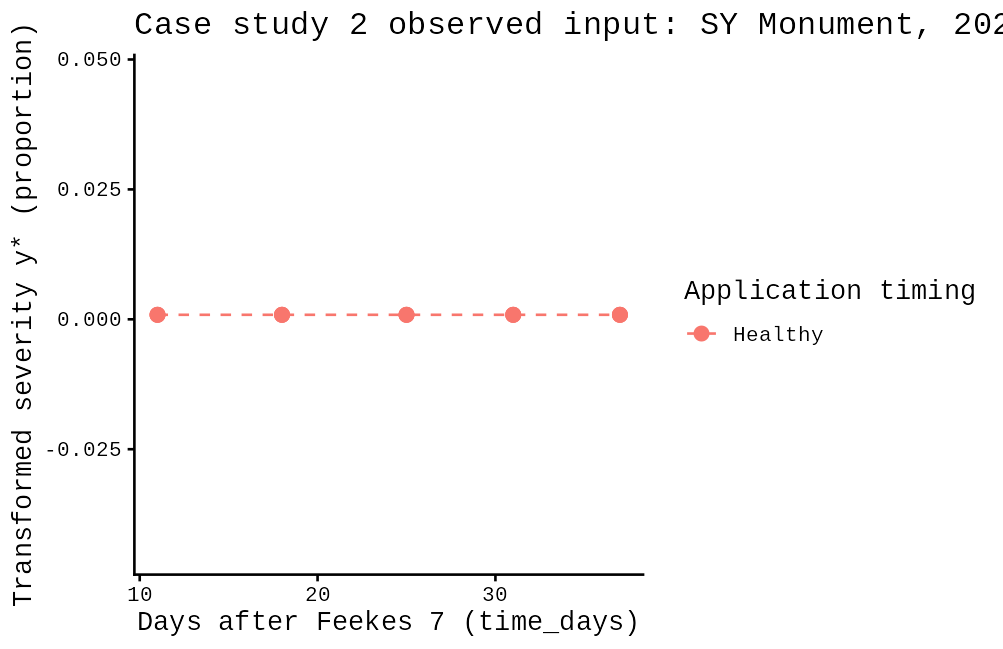

In [ ]:
from pathlib import Path
import subprocess
from IPython.display import Image, display

preview_r = """
library(readxl); library(dplyr); library(ggplot2)
data <- read_excel("Disease long - FRL.xlsx")
cat("Full workbook rows:", nrow(data), "\n")
cat("Columns:", paste(names(data), collapse = ", "), "\n")
N <- as.numeric(nrow(data))  # authors use the FULL workbook row count for y*
df_cs2 <- data %>% filter(trt == 2, year == "2024", var == "SY Monument")
df_cs2$y_star <- (((df_cs2$sev/100)*(N-1))+(1/2))/N
cat("Case study 2 rows:", nrow(df_cs2), "\n")
print(df_cs2[, c("time_days", "tim", "sev", "y_star")])
dir.create("figs", showWarnings = FALSE)
p <- ggplot(df_cs2, aes(time_days, y_star, colour = tim)) +
  geom_point(size = 2.8) +
  geom_line(linetype = "dashed") +
  labs(x = "Days after Feekes 7 (time_days)", y = "Transformed severity y* (proportion)",
       colour = "Application timing",
       title = "Case study 2 observed input: SY Monument, 2024 (trt 2)") +
  theme_classic(base_size = 13)
ggsave("figs/cs2_observed_input.png", p, width = 170, height = 110, units = "mm", dpi = 150)
"""
Path("/content/preview_input.R").write_text(preview_r)
subprocess.run(["Rscript", "/content/preview_input.R"], check=True, timeout=600, cwd="/content")
display(Image(filename="/content/figs/cs2_observed_input.png"))

### 5. Write the pinned R analysis — part 1: packages, data preparation, exploratory summaries

This (and the next three cells) writes the authors' R code from `Bay LDPC paper analysis.Rmd` @ `2a4a7f5` **verbatim** into `/content/cs2_analysis.R`, chunk by chunk, with a header comment marking the source chunk of each block. Part 1 is the authors' `Packages`, `Preparation`, and `Exploratory` chunks — the case-study filters and the y* transformation shown above. No cell is executed yet; the complete script is run in section 7 so all author chunks share one R session exactly as in the original Rmd.

**日本語:** 著者のRコードをチャンク単位でそのまま `/content/cs2_analysis.R` に書き込みます（このセルはPackages・Preparation・Exploratory部分）。実行は第7節で一括して行います。

In [ ]:
from pathlib import Path

r_part_1 = """
# ==== Author chunk 'Packages' (Bay LDPC paper analysis.Rmd @ 2a4a7f5) ====
library(readxl) # Import excel files
library(tidyverse) # Visualization and Wrangling
library(janitor) # Visualization and Wrangling
library(rjags) # Packge for Bayesian model implementation - Posterior sampler
library(gridExtra) # Visualization

# ==== Author chunk 'Preparation' (verbatim) ====
# Read the data
data <- read_excel("Disease long - FRL.xlsx")

# Calculating y*
N <- as.numeric(nrow(data))
data$y_star <- (((data$sev/100)*(N-1))+(1/2))/N

# Prepare data for case studies
df_cs1 <- data %>%
  filter(trt %in% c(3, 4), year == "2024", var == "KS18B")

df_cs1_osv <- data %>%
  filter(trt %in% c(3, 4), year == "2023", var == "KS18B")

df_cs2 <- data %>%
  filter(trt == 2, year == "2024", var == "SY Monument")

# ==== Author chunk 'Exploratory' (verbatim) ====
summary(df_cs1)
summary(df_cs2)

cat("=== part 1 (data) done ===\n")
"""
Path("/content/cs2_analysis.R").write_text(r_part_1)
print("wrote part 1")

wrote part 1


### 6. Part 2: the authors' prior-prediction chunk (Figure 1 data)

The authors' `PriorPred` chunk, verbatim: it draws k = 5000 parameter sets from the **assumed priors** (`y₀ ~ U(0.001, 0.1)`, `K ~ Beta(6,2)`, `r ~ U(0, 0.5)`, `φ ~ Gamma(24,2)`) with the authors' seed `set.seed(1996)`, propagates each through the logistic process model `μ = K / (1 + ((K−y₀)/y₀)·exp(−r·x))` over days 0–55, draws a Beta data-model observation per day, and reshapes the results for Figure 1. This shows what the data would look like if only the priors were trusted — the baseline against which the case-study-2 posterior is compared.

**日本語:** 著者の`PriorPred`チャンクをそのまま実装：事前分布から5000組を著者の乱数シードで抽出し、ロジスティック過程モデルとBetaデータモデルから事前予測を生成します（Figure 1のデータ）。

In [ ]:
from pathlib import Path

r_part_2 = """
# ==== Author chunk 'PriorPred' (verbatim) ====
# Iteration number and day in which we want to make a prediction
k <- 5000
x <- seq(0, 55, by = 1)

# Save the samples
prior.pred.y <- matrix(NA, nrow = k, ncol = length(x))
prior.pred.mu <- matrix(NA, nrow = k, ncol = length(x))

sample.y_0 <- rep(0, k)
sample.K <- rep(0, k)
sample.r <- rep(0, k)
sample.phi <- rep(0, k)

set.seed(1996)

for(i in 1:k) {

  # Sample from assumed prior distributions
  y_0 = runif(1, 0.001, 0.1)
  K = rbeta(1, 6, 2)
  r = runif(1, 0, 0.5)
  phi = rgamma(1, 24, 2)

  # Prior predictions
  ## Process model
  mu = K/(1 + ((K-y_0)/y_0)*exp(-r*x))

  ## Prior predictive draws from data model
  alpha = mu*phi
  beta = (1-mu)*phi
  y <- rbeta(length(x), alpha, beta)

  ## Saving prior predictive draws
  prior.pred.mu[i, ] <- mu
  prior.pred.y[i, ] <- y

  # Save the parameter samples
  sample.y_0[i] = y_0
  sample.K[i] = K
  sample.r[i] = r
  sample.phi[i] = phi

}

# Datasets with prior predictions - Parameters + Simulated y
par.prior.pred <- data.frame(
  y_0 = sample.y_0,
  K = sample.K,
  r = sample.r,
  phi = sample.phi
)

y.prior.pred <- data.frame()

for(i in seq_along(x)){
  temp <- data.frame(
    day = x[i],
    y.sim = prior.pred.y[, i],
    mu.sim = prior.pred.mu[, i])

  y.prior.pred <- rbind(y.prior.pred, temp)
}

# 50 predicted curves (mean)
ppred_mu <- data.frame(prior.pred.mu)
ppred_50 <- ppred_mu[sample(nrow(ppred_mu), 50, replace = FALSE), ]
colnames(ppred_50) <- seq(0, 55, by = 1)

ppred_50$id <- 1:nrow(ppred_50)

ppred_50_l <- pivot_longer(ppred_50, cols = 1:56, values_to = "p_draw", names_to = "time")

ppred_50_l$time <- as.numeric(ppred_50_l$time)
ppred_50_l <- arrange(ppred_50_l, time, by_group = id)

cat("=== part 2 (prior prediction) done ===\n")
"""
with open("/content/cs2_analysis.R", "a") as f:
    f.write(r_part_2)
print("wrote part 2")

wrote part 2


### 7. Part 3: the case-study-2 JAGS model, MCMC, summaries, diagnostics, predictive check

The authors' chunks `cs2 model fit`, `summaries CS2`, `cs2 model diag`, and `cs2 model check`, verbatim. The JAGS model is the paper's framework: `y[i] ~ dbeta(mu[i]*phi, (1-mu[i])*phi)` with the logistic curve `mu[i] <- K/(1+((K-y0)/y0)*exp(-r*x[i]))` and priors `phi ~ dgamma(24, 2)`, `K ~ dbeta(6, 2)`, `y0 ~ dunif(0.001, 0.1)`, `r ~ dunif(0, 0.5)`; it also draws `y_rep` (posterior replicated observations, used for the in-sample 95% coverage check) and `y_pred` on days 1–55 (posterior prediction). MCMC: 3 chains, 5000 burn-in/adaptation, 10000 posterior samples — exactly as in the source. Two AI-added lines (clearly marked) export the posterior summaries and the observed coverage to `/content/outputs/` for the results table in section 8. *Expect:* printed means/quantiles, Gelman–Rubin R-hat near 1, effective sample sizes, and a coverage value near the paper's 100% for case study 2.

**日本語:** 著者のケーススタディ2用JAGSモデル（3チェーン・バーンイン5000・サンプル10000、事前分布も論文どおり）をそのまま実行します。R-hat・実効サンプル数・95%事後予測カバレッジが出力され、要約はCSVに書き出されます（書き出し2行のみAI追記）。

In [ ]:
from pathlib import Path

r_part_3 = """
# ==== Author chunk 'cs2 model fit' (verbatim) ====
# Initialization
df <- df_cs2

## Posterior prediction components
x.new <- seq(1, 55)
N_pred <- length(x.new)

## Data and initial values
data_lines <- list(
  "y" = df$y_star,
  "x" = df$time_days,
  "N" = nrow(df),
  "x.new" = x.new,
  "N_pred" = N_pred
) # Data and sizes of groups

initials <- list(
  "K" = rep(0.5),
  "y0" = rep(0.05),
  "r" = rep(0.3),
  "phi" = rep(0.1)
) # Initial values for each chain

# Writting the model

model_jags_string <- "model {

  # Likelihood
  for(i in 1:N){
    y[i] ~ dbeta(alpha[i], beta[i])

    alpha[i] <- mu[i]*phi
    beta[i] <- (1-mu[i])*phi

    mu[i] <- K/(1+((K-y0)/y0)*exp(-r*x[i]))

    # Posterior replicated observation for calibration check
    y_rep[i] ~ dbeta(alpha[i], beta[i])
  }

  # Priors
    phi ~ dgamma(24, 2)
    K ~ dbeta(6, 2)
    y0 ~ dunif(0.001, 0.1)
    r ~ dunif(0, 0.5)

  # Posterior prediction
  for(j in 1:N_pred){
    y_pred[j] ~ dbeta(alpha.new[j], beta.new[j])

    alpha.new[j] <- mu.pred[j]*phi
    beta.new[j] <- (1-mu.pred[j])*phi

    mu.pred[j] <- K/(1+((K-y0)/y0)*exp(-r*x.new[j]))
    }
}"

# Fitting the model
m2 <- jags.model(textConnection(model_jags_string), inits = initials, data = data_lines, n.chains = 3) # Initialize the chains

update(m2, n.iter = 5000) # Burn-in / Adaptation

m2_samples <- coda.samples(m2, variable.names = c("K", "r", "y0", "phi", "y_pred", "y_rep"), n.iter = 10000) # Samples from the posterior distribution

# Checking results - Example
post_df2 <- as.data.frame(as.matrix(m2_samples))

# ==== Author chunk 'summaries CS2' (verbatim) ====
# K
mean(post_df2$K)
quantile(post_df2$K, c(0.025, 0.975))

# r
mean(post_df2$r)
quantile(post_df2$r, c(0.025, 0.975))

# y0
mean(post_df2$y0)
quantile(post_df2$y0, c(0.025, 0.975))

# ==== Author chunk 'cs2 model diag' (verbatim) ====
# Samples for diagnostic
m2_diag <- coda.samples(m2, variable.names = c("K", "r", "y0", "phi"), n.iter = 10000)

# Traceplots - Supplementary Figure 3

# Potetial scale reduction factor (R_hat)
gelman.diag(m2_diag)

# Effective sample size
effectiveSize(m2_diag)

# ==== Author chunk 'cs2 model check' (verbatim) ====
# In sample posterior predictive check
y.rep_df2 <- select(post_df2, starts_with("y_rep"))

y.rep2_sum <- apply(y.rep_df2, 2, quantile, probs = c(0.025, 0.975))

y.rep2_sum <- t(y.rep2_sum)

ppc2_check <- data.frame(
  observed = df$y_star,
  PPI.L = y.rep2_sum[, "2.5%"],
  PPI.U = y.rep2_sum[, "97.5%"]
)

ppc2_check$covered <- with(ppc2_check, observed >= PPI.L & observed <= PPI.U)

mean(ppc2_check$covered)

# ==== AI-added export (documented adaptation, no algorithm change) ====
cs2_summary <- data.frame(
  parameter = c("K", "r", "y0", "phi"),
  mean = c(mean(post_df2$K), mean(post_df2$r), mean(post_df2$y0), mean(post_df2$phi)),
  q025 = c(quantile(post_df2$K, 0.025), quantile(post_df2$r, 0.025),
           quantile(post_df2$y0, 0.025), quantile(post_df2$phi, 0.025)),
  q975 = c(quantile(post_df2$K, 0.975), quantile(post_df2$r, 0.975),
           quantile(post_df2$y0, 0.975), quantile(post_df2$phi, 0.975))
)
dir.create("outputs", showWarnings = FALSE)
write.csv(cs2_summary, "outputs/cs2_posterior_summary.csv", row.names = FALSE)
coverage <- mean(ppc2_check$covered)
cat("In-sample 95% posterior predictive coverage (case study 2):", coverage, "\n")
writeLines(as.character(coverage), "outputs/cs2_coverage.txt")

cat("=== part 3 (model fit) done ===\n")
"""
with open("/content/cs2_analysis.R", "a") as f:
    f.write(r_part_3)
print("wrote part 3")

wrote part 3


### 8. Part 4: the authors' figures for case study 2 (Figures 1, 7, 8)

The authors' `Fig1`, `Fig7`, and `Fig8` chunks, verbatim: (1) the prior-prediction figure — 95% ribbon of prior predictive observations plus 50 individual prior curves; (2) posterior histograms of K, r, y₀ for case study 2; (3) posterior predicted severity curves with 95% posterior predictive intervals **and the observed case-study-2 points overlaid**. The authors' `ggsave(...tiff...)` exports are commented out in the source; the only adaptation is saving the same figures as PNG under `/content/figs/` for display. *Expect:* three PNG files written.

**日本語:** 著者のFig1（事前予測）・Fig7（事後分布）・Fig8（事後予測曲線＋観測点）をそのまま生成します。TIFF書き出し行は元コードで無効化されているため、同じ図をPNGとして保存する点のみが追加です。

In [ ]:
from pathlib import Path

r_part_4 = r"""
# ==== Author chunk 'Fig1' (verbatim) ====
y.prior.sum <- y.prior.pred %>%
  group_by(day) %>%
  summarise(mean = mean(y.sim), lower = quantile(y.sim, 0.025), upper = quantile(y.sim, 0.975))

fig1_a <- ggplot(y.prior.sum, aes(x = day, y = mean)) +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.3) +
  geom_line() +
  theme_classic(base_size = 14) +
  theme(text = element_text(family = "sans"), plot.tag = element_text(face = "bold", size = 16)) +
  labs(x = "Day", y = "Prior predicted severity (prop.)", tag = "a")

fig1_b <- ggplot(ppred_50_l, aes(time, p_draw, group = id)) +
  geom_line() +
  theme_classic(base_size = 14) +
  theme(text = element_text(family = "sans"), , plot.tag = element_text(face = "bold", size = 16)) +
  labs(x = "Day", y = "Prior predicted severity (prop.)", tag = "b")

fig1 <- grid.arrange(fig1_a, fig1_b, ncol = 1)

# ==== AI-added PNG export (authors' tiff ggsave lines are commented out in source) ====
dir.create("figs", showWarnings = FALSE)
ggsave("figs/fig1_prior_prediction.png", fig1, width = 170, height = 205, units = "mm", dpi = 150)

# ==== Author chunk 'Fig7' (verbatim) ====
# Individual plots
K2_plot <- ggplot(post_df2) +
  geom_histogram(aes(post_df2$K, after_stat(density), fill = "Healthy check"), alpha = 0.5, color = "black") +
  labs(y = "[K]", x = "K") +
  scale_fill_manual(name = "App. timing", values = ("Healthy check" = "#21538B")) +
  theme(text = element_text(family = "sans")) +
  theme_classic(base_size = 14)

r2_plot <- ggplot(post_df2) +
  geom_histogram(aes(post_df2$r, after_stat(density), fill = "Healthy check"), alpha = 0.5, color = "black") +
  labs(y = "[r]", x = "r") +
  scale_fill_manual(name = "App. timing", values = ("Healthy check" = "#21538B")) +
  theme(text = element_text(family = "sans")) +
  theme_classic(base_size = 14)

y02_plot <- ggplot(post_df2) +
  geom_histogram(aes(post_df2$y0, after_stat(density), fill = "Healthy check"), alpha = 0.5, color = "black") +
  labs(y = expression("["*y[0]*"]"), x = expression(y[0])) +
  scale_fill_manual(name = "App. timing", values = ("Healthy check" = "#21538B")) +
  theme(text = element_text(family = "sans")) +
  theme_classic(base_size = 14)

fig7 <- grid.arrange(K2_plot, r2_plot, y02_plot, nrow = 3)

ggsave("figs/fig7_cs2_posteriors.png", fig7, width = 170, height = 205, units = "mm", dpi = 150)

# ==== Author chunk 'Fig8' (verbatim) ====
post_df <- select(post_df2, starts_with("y_pred"))

post.df_sum <- data.frame(
  mean = apply(post_df, 2, mean),
  PPI.L = apply(post_df, 2, quantile, 0.025),
  PPI.U = apply(post_df, 2, quantile, 0.975)
)

post.df_sum$id <- row.names(post.df_sum)

post.df_sum <- post.df_sum %>%
  separate(id, c("id", "day"), sep = "\\[") %>%
  mutate(day = gsub("\\]", "", day)) %>%
  transform(day = as.numeric(day))

fig8 <- ggplot(post.df_sum, aes(day, mean, colour = "Healthy check", fill = "Healthy check")) +
  geom_line(linewidth = 0.8) +
  geom_ribbon(aes(ymin = PPI.L, ymax = PPI.U), alpha = 0.15) +
  geom_point(data = df_cs2, aes(x = time_days, y = y_star, shape = tim), inherit.aes = FALSE) +
  scale_discrete_manual(name = "App. timing", aesthetics = c("colour", "fill"), values = ("Healthy check" = "#21538B")) +
  theme_classic(base_size = 14) +
  guides(shape = "none") +
  labs(y = "Posterior predicted severity (prop.)", x = "Day")

ggsave("figs/fig8_cs2_posterior_prediction.png", fig8, width = 170, height = 110, units = "mm", dpi = 150)

cat("=== part 4 (figures) done ===\n")
"""
with open("/content/cs2_analysis.R", "a") as f:
    f.write(r_part_4)
print("wrote part 4")

wrote part 4


### 9. Run the complete pinned R analysis

This cell runs the whole `/content/cs2_analysis.R` — the authors' chunks above, in their original Rmd order, in a single R session — with `Rscript` (checked subprocess, 40-minute timeout). All printed output is the authors' own R output: data summaries, JAGS chain messages, posterior means/quantiles, Gelman–Rubin diagnostics, effective sample sizes, the in-sample coverage, and `done` markers for each part. *Expect:* completion within a few minutes with no error exit.

**日本語:** 著者チャンクを元の順序・単一Rセッションで一括実行します（Rscript、チェック付きサブプロセス）。出力はすべて著者コード自身のものです。

In [ ]:
import subprocess

result = subprocess.run(
    ["Rscript", "/content/cs2_analysis.R"],
    check=True,
    timeout=2400,
    cwd="/content",
)
print("Rscript exit code:", result.returncode)

Rscript exit code: 0


### 10. Results table (case study 2 posterior)

The posterior summaries written by the R script (authors' `summaries CS2` quantities) are loaded and displayed, together with the observed in-sample 95% posterior predictive coverage. *Expected pattern from the paper's flow:* in-sample coverage for case study 2 near the nominal 95–100% (the investigation's summary of the paper reports 100% for case study 2), and the K posterior resembling its Beta(6,2) prior while r and y₀ shift toward lower values (low-severity epidemic carrying limited information). Exact numbers vary slightly per MCMC run.

**日本語:** Rスクリプトが書き出した事後要約（K, r, y₀, φの平均と95%区間）と、サンプル内95%事後予測カバレッジを表示します。論文の記述ではケーススタディ2のカバレッジは100%とのことです。

In [ ]:
from pathlib import Path
import pandas as pd

summary = pd.read_csv("/content/outputs/cs2_posterior_summary.csv")
coverage = float(Path("/content/outputs/cs2_coverage.txt").read_text().strip())
print("In-sample 95% posterior predictive coverage (case study 2):", coverage)
print()
display(summary)

In-sample 95% posterior predictive coverage (case study 2): 1.0



,parameter,mean,q025,q975
0,K,0.749424,0.414428,0.962872
1,r,0.016146,0.000525,0.049747
2,y0,0.013461,0.004408,0.025988
3,phi,13.344928,8.793163,19.041961


### 11. Display the executed figures

The three figures generated by the authors' figure chunks are displayed from the PNGs saved on the Colab VM: the paper's Figure 1 (prior prediction), Figure 7 (case-study-2 posteriors), and Figure 8 (posterior predicted curves with the observed points). These are actual outputs of this run, not copies of the paper's figures.

**日本語:** この実行で生成されたFigure 1・7・8を表示します（論文図のコピーではなく本実行の出力です）。

Figure 8 (authors' chunk): case-study-2 posterior predicted severity with observed points (y*)


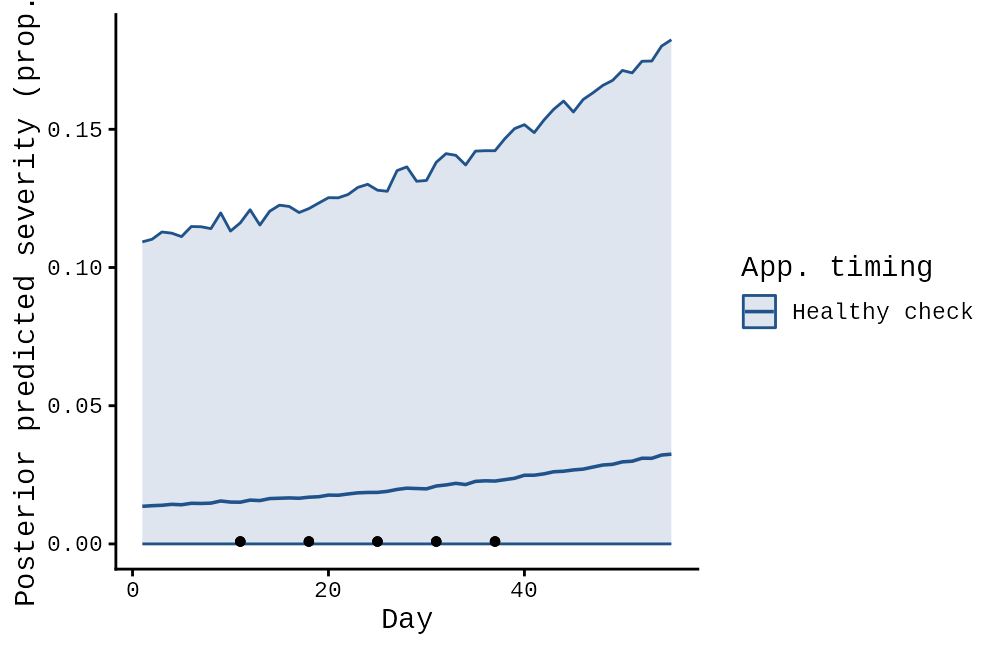

Figure 1 (authors' chunk): prior-prediction summary and 50 individual prior curves


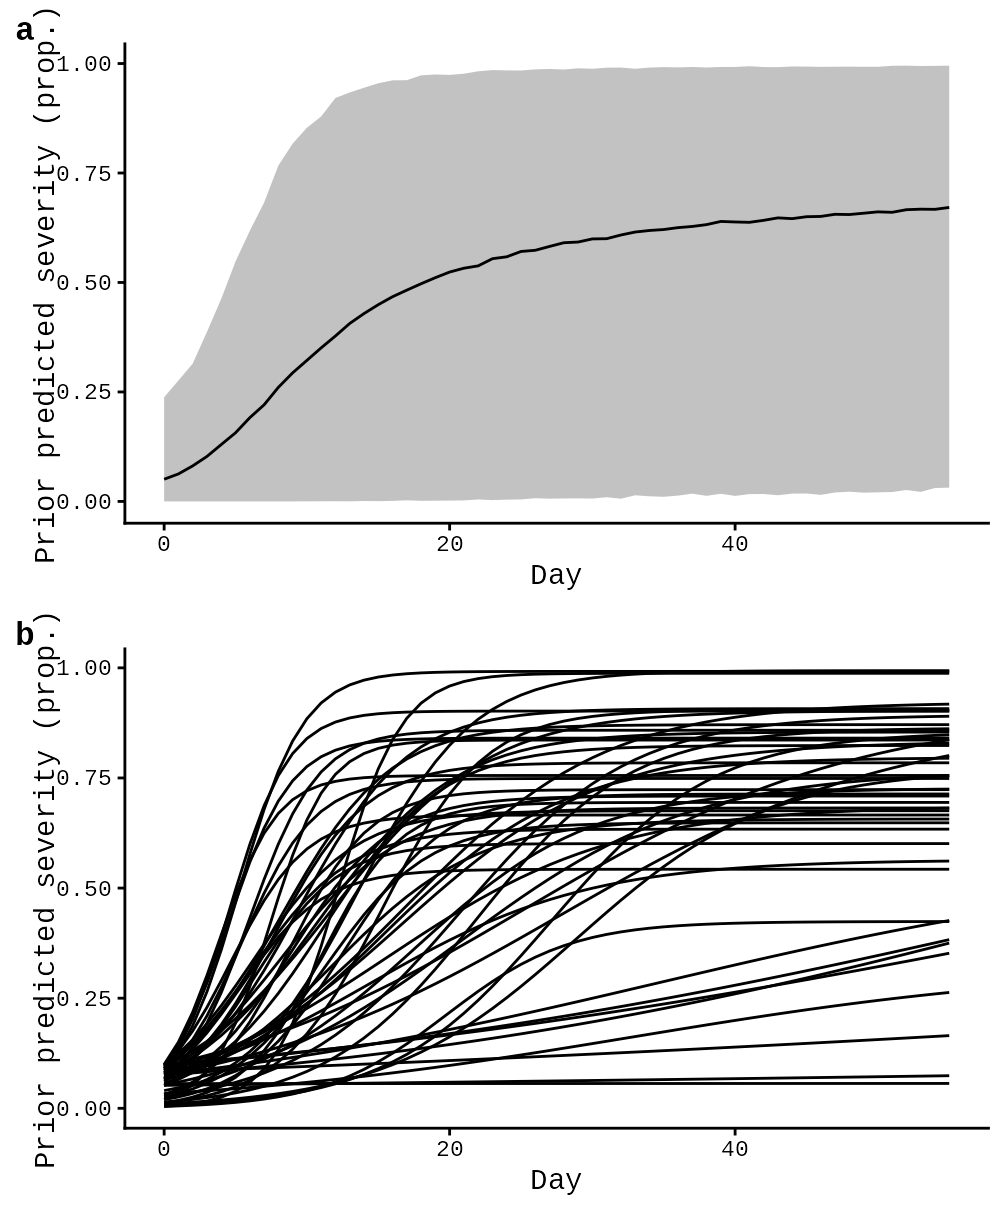

Figure 7 (authors' chunk): case-study-2 posterior distributions of K, r, y0


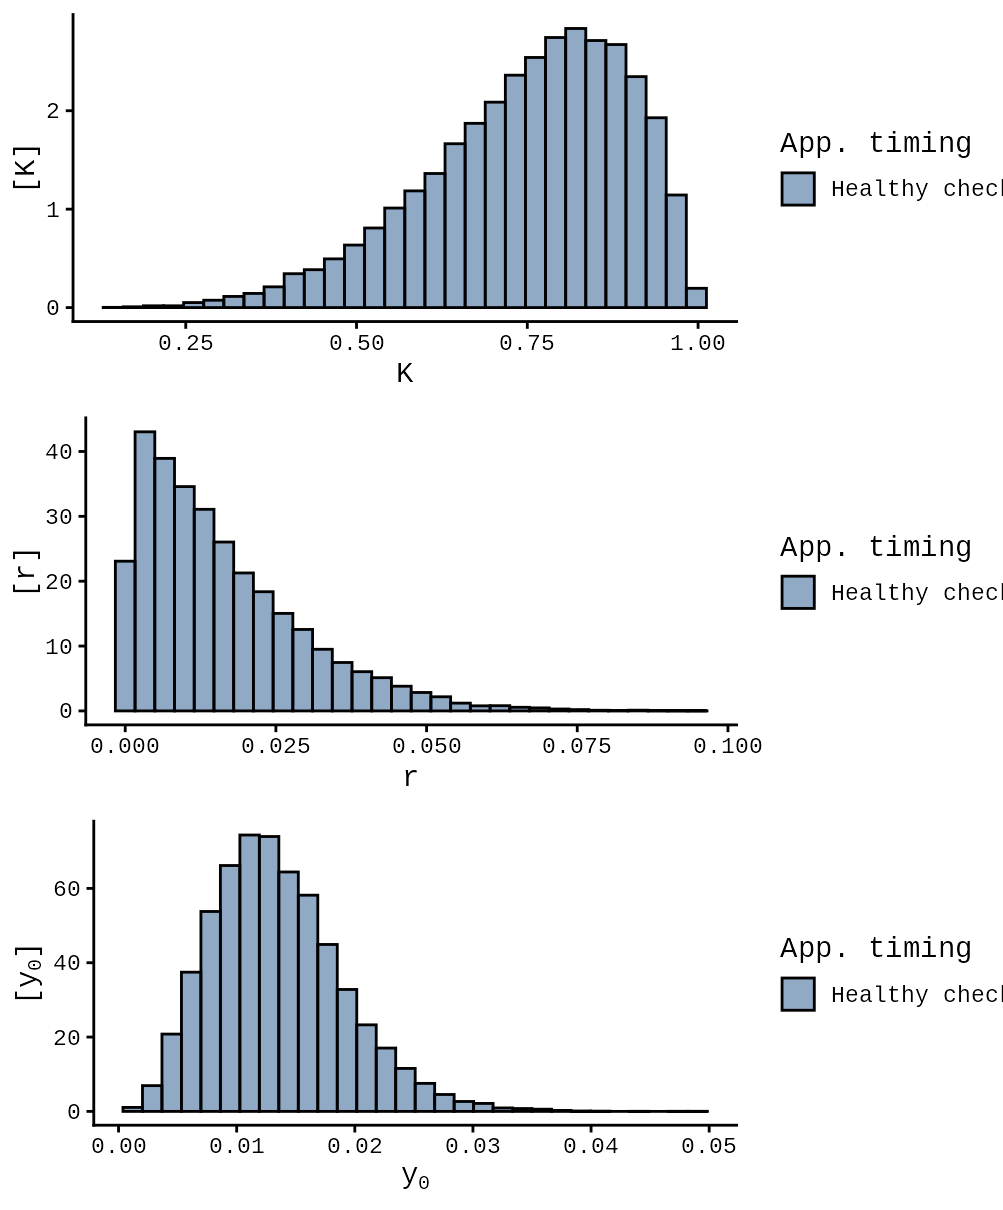

In [ ]:
from IPython.display import Image, display

for path, caption in [
    ("/content/figs/fig8_cs2_posterior_prediction.png", "Figure 8 (authors' chunk): case-study-2 posterior predicted severity with observed points (y*)"),
    ("/content/figs/fig1_prior_prediction.png", "Figure 1 (authors' chunk): prior-prediction summary and 50 individual prior curves"),
    ("/content/figs/fig7_cs2_posteriors.png", "Figure 7 (authors' chunk): case-study-2 posterior distributions of K, r, y0"),
]:
    print(caption)
    display(Image(filename=path))

## Interpretation, scope, and validation record

**What was executed.** The authors' case-study-2 analysis — data transformation (`y*` with full-workbook N), prior prediction with their seed, JAGS MCMC (3 chains, 5000 burn-in, 10000 samples, priors `K ~ Beta(6,2)`, `y0 ~ U(0.001,0.1)`, `r ~ U(0,0.5)`, `phi ~ Gamma(24,2)`), posterior summaries, Gelman–Rubin diagnostics, effective sample sizes, in-sample 95% posterior predictive coverage, and Figures 1/7/8 — as pinned at commit `2a4a7f5` of `Bay LDPC paper analysis.Rmd`.

**What was not executed.** Case study 1 (treatment contrasts of K, r, AUDPC, r\*; 2024 KS18B trt 3/4 fits plus 2023 out-of-season validation), the supplementary block-random-effects model (which is `eval=FALSE` in the source Rmd), and supplementary figures. The full paper text was not read for this minimal demonstration: every executed parameter is fixed by the pinned author code, and the PhenoPaper study flow was used only as prior research guidance.

**Differences from the paper's own runs.** (1) Chunk subset as scoped above; (2) figures saved as PNG instead of the (commented-out) TIFF export; (3) AI-added, clearly marked CSV/txt export of summaries; (4) execution via `Rscript` in a single session instead of RStudio knitting. No numerical operation, prior, seed, filter, or MCMC setting was changed. Case-study-2 MCMC results vary slightly between runs; the paper's qualitative finding for case study 2 — K posterior resembling its prior, r and y₀ shifting lower, high in-sample coverage — should be reproduced qualitatively.

**Environment note.** Validated on a fresh Colab CPU runtime; free-tier runtime versions and availability may differ.

**References.** Silva Jr., C.D. et al. *Bayesian Logistic Disease Progress Curves for Modeling Plant Disease Epidemics*, Research Square preprint rs-11484962/v1. Author code: github.com/ClaudioDSJr11/Bayesian-Logistic-Disease-Progress-Curve-Paper @ `2a4a7f5` (no LICENSE file present — reuse with attribution).

**日本語:** 本ノートブックで実行したのはケーススタディ2の解析一式（y*変換、事前予測、JAGS MCMC、事後要約、収束診断、カバレッジ、Figure 1/7/8）です。ケーススタディ1・補足モデルは未実行です。数値操作・事前分布・乱数シード・フィルタ・MCMC設定は一切変更していません。検証は新規のColab CPUランタイムで実施しました。